In [12]:
# =============================================================
# 1. Imports and Setup
# =============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
import random
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import albumentations as A
import cv2
import warnings
warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("✅ Using device:", device)

✅ Using device: cuda


In [13]:
# 2. Paths and Imports
# =============================================================

import os
import random
import numpy as np
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader, random_split
import albumentations as A

# =============================================================
# 2. Paths
# =============================================================

base_dir = "/kaggle/input/datasets/kartikmaity/tnbc-patient-dataset/TNBC_Dataset_Patient_Split"

# -------------------------------------------------------------
# Paths
# -------------------------------------------------------------

train_img_dir = os.path.join(base_dir,"Train/image")
train_mask_dir = os.path.join(base_dir,"Train/Mask")

test_img_dir = os.path.join(base_dir,"Test/image")
test_mask_dir = os.path.join(base_dir,"Test/Mask")

val_img_dir = os.path.join(base_dir, "Validation/image")
val_mask_dir = os.path.join(base_dir, "Validation/Mask")

IMG_SIZE = 256
BATCH_SIZE = 2
SEED = 42
torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

# =============================================================
# 3. Dataset Class
# =============================================================

class MonuSegDataset(Dataset):
    def __init__(self, img_dir, mask_dir, indices=None, transform=None):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.transform = transform
        
        self.images = sorted(os.listdir(img_dir))
        self.masks = sorted(os.listdir(mask_dir))
        
        if indices is not None:
            self.images = [self.images[i] for i in indices]
            self.masks = [self.masks[i] for i in indices]

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.images[idx])
        mask_path = os.path.join(self.mask_dir, self.masks[idx])

        image = np.array(Image.open(img_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))) / 255.0
        mask = np.array(Image.open(mask_path).convert("L").resize((IMG_SIZE, IMG_SIZE))) / 255.0
        mask = np.where(mask > 0.5, 1, 0).astype(np.float32)

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"]

        image = torch.tensor(image).permute(2, 0, 1).float()
        mask = torch.tensor(mask).unsqueeze(0).float()

        return image, mask

# =============================================================
# Augmentations
# =============================================================
train_transform = A.Compose([
    A.Resize(512, 512),
    A.RandomCrop(height=512, width=512, always_apply=True),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.01, scale_limit=(-0.04,0.04), rotate_limit=(-15,15), p=0.5),
])

#val_transform = None

val_transform = A.Compose([
    A.Resize(512, 512),
    # ToTensorV2(),
])

test_transform = A.Compose([
    A.Resize(512, 512),
    # ToTensorV2(),
])



train_dataset = MonuSegDataset(train_img_dir, train_mask_dir, indices=None, transform=train_transform)
val_dataset = MonuSegDataset(val_img_dir, val_mask_dir, indices=None, transform=val_transform)
test_dataset = MonuSegDataset(test_img_dir, test_mask_dir, indices=None, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

# -------------------------------------------------------------
# Summary
# -------------------------------------------------------------

print("\n✅ Dataset loaded successfully!")

print(
    f"Train: {len(train_dataset)} | "
    f"Validation: {len(val_dataset)} | "
    f"Test: {len(test_dataset)}"
)

print(
    f"Total used: "
    f"{len(train_dataset) + len(val_dataset) + len(test_dataset)}"
)


✅ Dataset loaded successfully!
Train: 33 | Validation: 10 | Test: 7
Total used: 50


In [14]:
# 5. U-Net + resnet50 Model
# =============================================================
from torchinfo import summary
import torch
import torch.nn as nn
import torchvision.models as models


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.double_conv(x)


class UNet_Backbone_change(nn.Module):
    def __init__(self, n_channels=3, n_classes=1):
        super().__init__()
        resnet = models.resnet50(weights="DEFAULT")
        self.conv1 = resnet.conv1
        self.bn1 = resnet.bn1
        self.relu = resnet.relu
        self.maxpool = resnet.maxpool

        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3
        self.layer4 = resnet.layer4

       
        self.up1 = nn.ConvTranspose2d(2048, 1024, 2, stride=2)
        self.dec1 = DoubleConv(2048,1024)
        self.up2 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec2 = DoubleConv(1024,512)
        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = DoubleConv(512, 256)
        self.up4 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec4 = DoubleConv(192, 128)

        self.up5 = nn.ConvTranspose2d(128,64, 2, stride=2)
        self.final = nn.Conv2d(64, n_classes, 1)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)

        c0=x

        x = self.maxpool(x)

        c1 = self.layer1(x)
        c2 = self.layer2(c1)
        c3 = self.layer3(c2)
        c4 = self.layer4(c3)


        d1 = self.up1(c4)
        d1 = torch.cat([d1, c3], dim=1)
        d1 = self.dec1(d1)

        d2 = self.up2(d1)
        d2 = torch.cat([d2, c2], dim=1)
        d2 = self.dec2(d2)

        d3 = self.up3(d2)
        d3 = torch.cat([d3, c1], dim=1)
        d3 = self.dec3(d3)

        d4 = self.up4(d3)
        d4 = torch.cat([d4, c0], dim=1)
        d4 = self.dec4(d4)

        d5= self.up5(d4)

        return torch.sigmoid(self.final(d5))


# =============================================================
# Print Model Summary
# =============================================================
if __name__ == "__main__":
    model = UNet_Backbone_change(n_channels=3, n_classes=1)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device)

    
    print("\n================= MODEL SUMMARY =================\n")
    print(summary(model, input_size=(4, 3, 256, 256)))


================= MODEL SUMMARY =================

Layer (type:depth-idx)                   Output Shape              Param #
UNet_Backbone_change                     [4, 1, 256, 256]          --
├─Conv2d: 1-1                            [4, 64, 128, 128]         9,408
├─BatchNorm2d: 1-2                       [4, 64, 128, 128]         128
├─ReLU: 1-3                              [4, 64, 128, 128]         --
├─MaxPool2d: 1-4                         [4, 64, 64, 64]           --
├─Sequential: 1-5                        [4, 256, 64, 64]          --
│    └─Bottleneck: 2-1                   [4, 256, 64, 64]          --
│    │    └─Conv2d: 3-1                  [4, 64, 64, 64]           4,096
│    │    └─BatchNorm2d: 3-2             [4, 64, 64, 64]           128
│    │    └─ReLU: 3-3                    [4, 64, 64, 64]           --
│    │    └─Conv2d: 3-4                  [4, 64, 64, 64]           36,864
│    │    └─BatchNorm2d: 3-5             [4, 64, 64, 64]           128
│    │    └─ReLU: 3-

Epoch 1/100 [Val]: 100%|██████████| 5/5 [00:00<00:00,  5.97it/s]



Epoch 1/100
Train Loss: 0.6852 | Val Loss: 0.6717
Train Dice: 0.2186 | Val Dice: 0.2365
Train IoU : 0.3630 | Val IoU : 0.4137
✅ Best model saved (Epoch 1, Val Loss 0.6717)


Epoch 2/100 [Val]: 100%|██████████| 5/5 [00:00<00:00,  6.19it/s]



Epoch 2/100
Train Loss: 0.5889 | Val Loss: 0.5810
Train Dice: 0.2964 | Val Dice: 0.3053
Train IoU : 0.5554 | Val IoU : 0.5605
✅ Best model saved (Epoch 2, Val Loss 0.5810)


Epoch 3/100 [Val]: 100%|██████████| 5/5 [00:00<00:00,  6.11it/s]


...


Epoch 98/100
Train Loss: 0.0894 | Val Loss: 0.3171
Train Dice: 0.8846 | Val Dice: 0.6582
Train IoU : 0.8188 | Val IoU : 0.5144


Epoch 99/100 [Val]: 100%|██████████| 5/5 [00:00<00:00,  5.84it/s]



Epoch 99/100
Train Loss: 0.0854 | Val Loss: 0.2550
Train Dice: 0.8895 | Val Dice: 0.7402
Train IoU : 0.8268 | Val IoU : 0.6039


Epoch 100/100 [Val]: 100%|██████████| 5/5 [00:00<00:00,  5.74it/s]



Epoch 100/100
Train Loss: 0.0832 | Val Loss: 0.2671
Train Dice: 0.8951 | Val Dice: 0.7209
Train IoU : 0.8351 | Val IoU : 0.5809

🎉 Training Completed!
🏆 Best Epoch: 46
✔ Best Val Loss: 0.2243


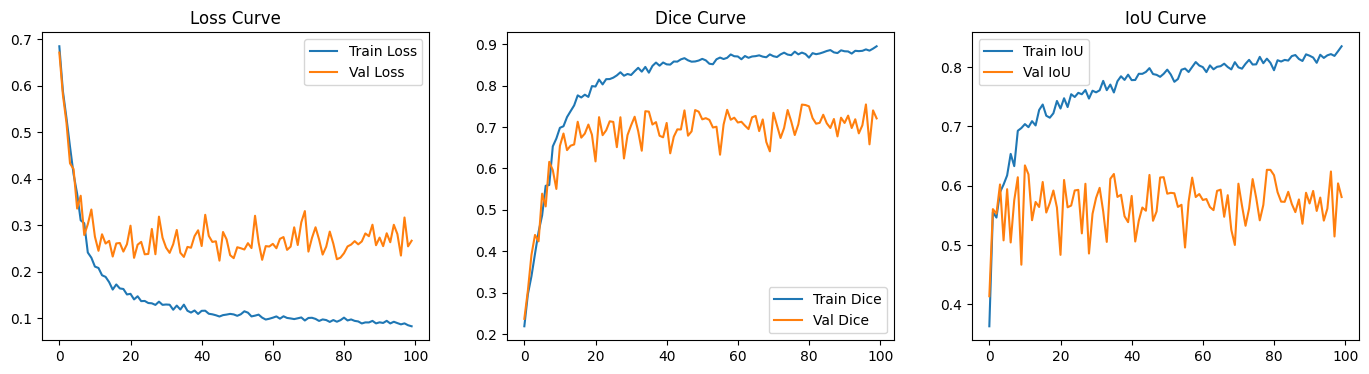

In [15]:
# =============================================================
# LOSS + METRICS
# =============================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm import tqdm
import copy
import matplotlib.pyplot as plt


# BCE + Dice Loss
class BCEDiceLoss(nn.Module):
    def __init__(self, smooth=1e-5):
        super().__init__()
        self.smooth = smooth
        self.bce = nn.BCELoss()

    def forward(self, preds, targets):
        bce_loss = self.bce(preds, targets)

        preds_f = preds.view(-1)
        targets_f = targets.view(-1)
        inter = (preds_f * targets_f).sum()
        dice_loss = 1 - (2 * inter + self.smooth) / \
                        (preds_f.sum() + targets_f.sum() + self.smooth)

        return 0.5 * bce_loss + 0.5 * dice_loss


# Dice Metric
def dice_coef(y_true, y_pred, smooth=1e-5):
    y_true_f = y_true.view(-1)
    y_pred_f = y_pred.view(-1)
    inter = (y_true_f * y_pred_f).sum()
    return (2. * inter + smooth) / (y_true_f.sum() + y_pred_f.sum() + smooth)


# IoU Metric
def iou_score(preds, masks, threshold=0.5, eps=1e-6):
    preds_bin = (preds > threshold).float()
    masks_bin = (masks > threshold).float()

    inter = (preds_bin * masks_bin).sum().item()
    union = preds_bin.sum().item() + masks_bin.sum().item() - inter

    return inter / (union + eps)


# =============================================================
# TRAINING LOOP
# =============================================================
def train_model(model, train_loader, val_loader, epochs=50):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device)

    criterion = BCEDiceLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    # Tracking curves
    train_losses, val_losses = [], []
    train_dice_scores, val_dice_scores = [], []
    train_iou_scores, val_iou_scores = [], []

    best_val_loss = float("inf")
    best_epoch = 0
    best_model_weights = None

    for epoch in range(epochs):

        # ------------------ TRAIN ------------------
        model.train()
        train_loss = train_dice = train_iou = 0

        for images, masks in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]"):
            images, masks = images.to(device), masks.to(device)

            preds = model(images)
            loss = criterion(preds, masks)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # Accumulate
            train_loss += loss.item()
            train_dice += dice_coef(masks, preds).item()
            train_iou += iou_score(preds, masks)

        # ------------------ VALIDATION ------------------
        model.eval()
        val_loss = val_dice = val_iou = 0

        with torch.no_grad():
            for images, masks in tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} [Val]"):
                images, masks = images.to(device), masks.to(device)

                preds = model(images)
                val_loss += criterion(preds, masks).item()
                val_dice += dice_coef(masks, preds).item()
                val_iou += iou_score(preds, masks)

        # ------------------ AVERAGES ------------------
        avg_train_loss = train_loss / len(train_loader)
        avg_val_loss   = val_loss / len(val_loader)
        avg_train_dice = train_dice / len(train_loader)
        avg_val_dice   = val_dice / len(val_loader)
        avg_train_iou  = train_iou / len(train_loader)
        avg_val_iou    = val_iou / len(val_loader)

        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)
        train_dice_scores.append(avg_train_dice)
        val_dice_scores.append(avg_val_dice)
        train_iou_scores.append(avg_train_iou)
        val_iou_scores.append(avg_val_iou)

        # ------------------ PRINT ------------------
        print(f"\nEpoch {epoch+1}/{epochs}")
        print(f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")
        print(f"Train Dice: {avg_train_dice:.4f} | Val Dice: {avg_val_dice:.4f}")
        print(f"Train IoU : {avg_train_iou:.4f} | Val IoU : {avg_val_iou:.4f}")

        # ------------------ SAVE BEST ------------------
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_epoch = epoch + 1
            best_model_weights = copy.deepcopy(model.state_dict())
            torch.save(model.state_dict(), "best_unet_monu.pth")
            print(f"✅ Best model saved (Epoch {epoch+1}, Val Loss {best_val_loss:.4f})")

    # ------------------ LOAD BEST MODEL ------------------
    model.load_state_dict(best_model_weights)

    print("\n🎉 Training Completed!")
    print(f"🏆 Best Epoch: {best_epoch}")
    print(f"✔ Best Val Loss: {best_val_loss:.4f}")

    return {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_dice": train_dice_scores,
        "val_dice": val_dice_scores,
        "train_iou": train_iou_scores,
        "val_iou": val_iou_scores,
    }


# =============================================================
# PLOTTING FUNCTION
# =============================================================
def plot_training(history):
    plt.figure(figsize=(17, 4))

    # Loss
    plt.subplot(1, 3, 1)
    plt.plot(history["train_losses"], label="Train Loss")
    plt.plot(history["val_losses"], label="Val Loss")
    plt.title("Loss Curve")
    plt.legend()

    # Dice
    plt.subplot(1, 3, 2)
    plt.plot(history["train_dice"], label="Train Dice")
    plt.plot(history["val_dice"], label="Val Dice")
    plt.title("Dice Curve")
    plt.legend()

    # IoU
    plt.subplot(1, 3, 3)
    plt.plot(history["train_iou"], label="Train IoU")
    plt.plot(history["val_iou"], label="Val IoU")
    plt.title("IoU Curve")
    plt.legend()

    plt.show()

model = UNet_Backbone_change().to(device)
history = train_model(model, train_loader, val_loader, epochs=100)
plot_training(history)

📥 Loading best model...
🧪 Evaluating on test set...


Evaluating Test Set: 100%|██████████| 7/7 [00:00<00:00, 11.85it/s]



🎯 TEST SET EVALUATION
✅ Dice Coefficient: 0.8309
✅ IoU (Jaccard):    0.7121

📊 Generating visualizations...


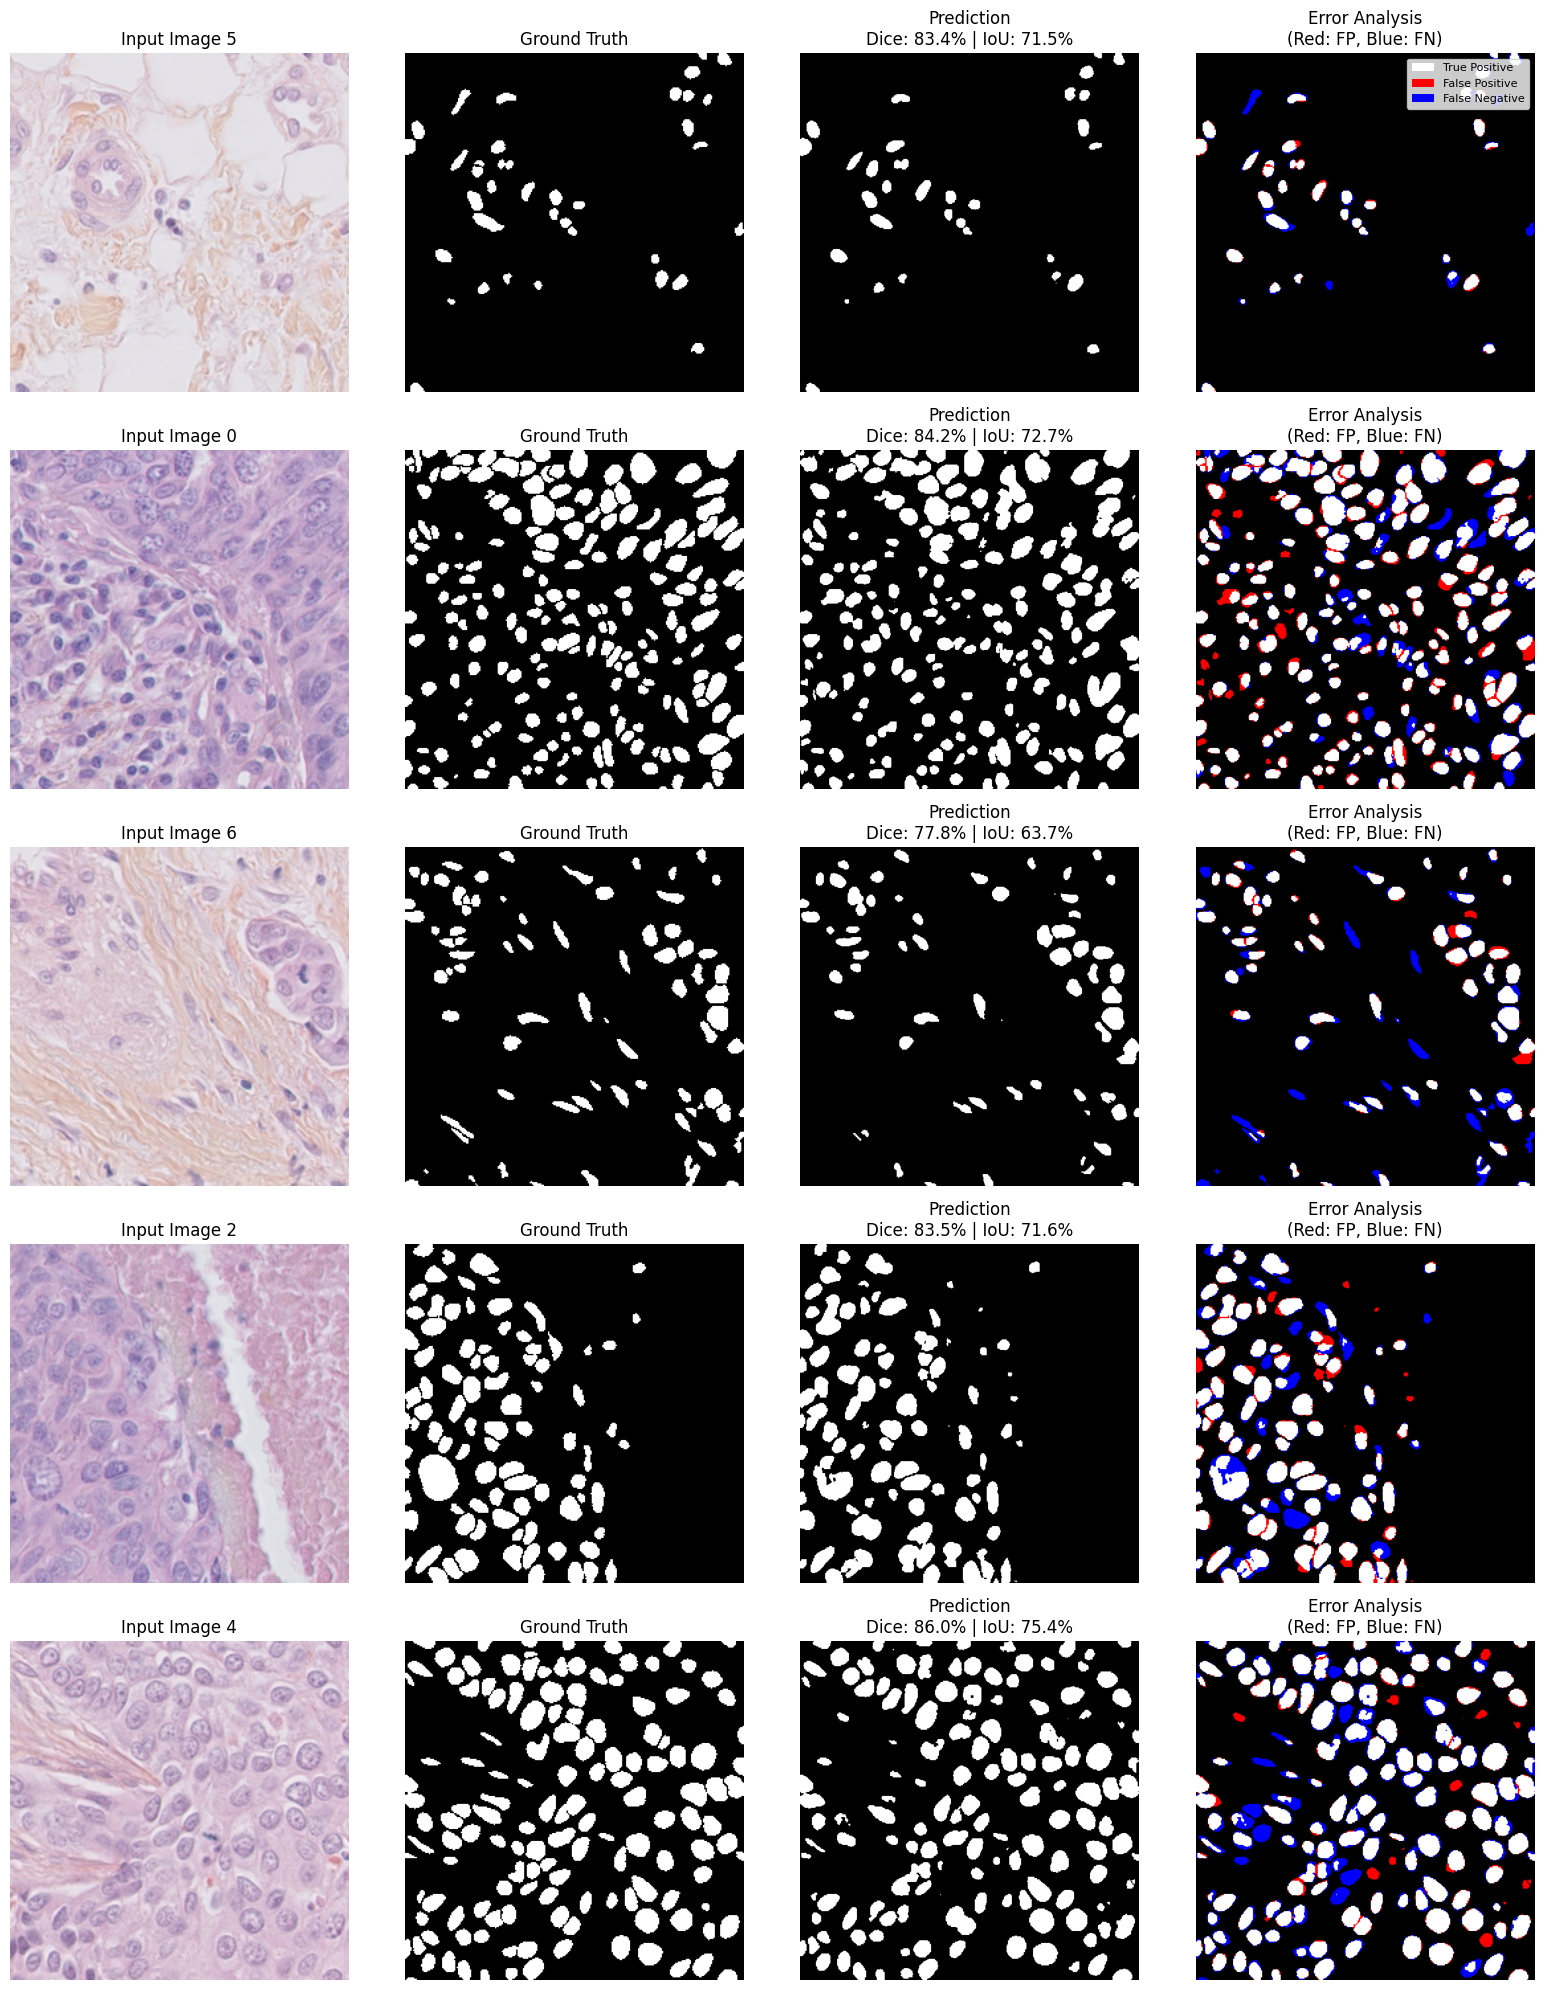


🎉 Evaluation completed successfully!


In [16]:
# =============================================================
# Simplified Test Evaluation (Only Dice and IoU)
# =============================================================

import numpy as np

def iou_coef(y_true, y_pred, smooth=1e-5):
    """
    Intersection over Union (IoU) metric for binary masks.
    """
    y_true_f = y_true.view(-1)
    y_pred_f = y_pred.view(-1)
    intersection = (y_true_f * y_pred_f).sum()
    union = y_true_f.sum() + y_pred_f.sum() - intersection
    return (intersection + smooth) / (union + smooth)

# Load the best model
print("📥 Loading best model...")
model.load_state_dict(torch.load("best_unet_monu.pth", map_location=device))
model.eval()

# Initialize accumulators for metrics
test_dice, test_iou = 0, 0

print("🧪 Evaluating on test set...")

# Loop through test data
with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Evaluating Test Set"):
        images, masks = images.to(device), masks.to(device)
        preds = model(images)
        preds_bin = (preds > 0.5).float()   # threshold at 0.5

        # Accumulate metrics
        test_dice += dice_coef(masks, preds_bin).item()
        test_iou += iou_coef(masks, preds_bin).item()

# Average metrics
num_batches = len(test_loader)
avg_test_dice = test_dice / num_batches
avg_test_iou = test_iou / num_batches

# Print simplified results
print("\n" + "="*40)
print("🎯 TEST SET EVALUATION")
print("="*40)
print(f"✅ Dice Coefficient: {avg_test_dice:.4f}")
print(f"✅ IoU (Jaccard):    {avg_test_iou:.4f}")
print("="*40)

# =============================================================
# Simplified Visualization (Only Dice and IoU)
# =============================================================

def dice_coef_single(y_true, y_pred, smooth=1e-5):
    """Compute Dice coefficient for one pair of masks"""
    y_true_f = y_true.flatten()
    y_pred_f = y_pred.flatten()
    intersection = np.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (np.sum(y_true_f) + np.sum(y_pred_f) + smooth)

def iou_coef_single(y_true, y_pred, smooth=1e-5):
    """Compute IoU for one pair of masks"""
    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred) - intersection
    return intersection / (union + smooth)

def visualize_predictions_simple(model, dataset, num_samples=5, threshold=0.5):
    """
    Simplified visualization with dice, iou and error analysis
    """
    indices = random.sample(range(len(dataset)), num_samples)
    fig, axes = plt.subplots(num_samples, 4, figsize=(16, num_samples * 4))
    
    if num_samples == 1:
        axes = axes.reshape(1, -1)
    
    for i, idx in enumerate(indices):
        image, mask = dataset[idx]

        with torch.no_grad():
            pred_prob = model(image.unsqueeze(0).to(device)).cpu().squeeze().numpy()

        pred_mask = (pred_prob > threshold).astype(np.uint8)
        true_mask = mask.squeeze().numpy().astype(np.uint8)
        
        # Compute metrics
        dice_score = dice_coef_single(true_mask, pred_mask) * 100
        iou_score = iou_coef_single(true_mask, pred_mask) * 100
        
        # Create error map (FP: red, FN: blue, TP: white, TN: black)
        error_map = np.zeros((*true_mask.shape, 3), dtype=np.uint8)
        true_positive = (true_mask == 1) & (pred_mask == 1)
        false_positive = (true_mask == 0) & (pred_mask == 1)
        false_negative = (true_mask == 1) & (pred_mask == 0)
        
        error_map[true_positive] = [255, 255, 255]  # White for TP
        error_map[false_positive] = [255, 0, 0]     # Red for FP
        error_map[false_negative] = [0, 0, 255]     # Blue for FN

        # Plot 1: Original Image
        axes[i, 0].imshow(image.permute(1, 2, 0) if image.shape[0] == 3 else image.squeeze(), cmap='gray')
        axes[i, 0].set_title(f"Input Image {idx}")
        axes[i, 0].axis("off")
        
        # Plot 2: Ground Truth
        axes[i, 1].imshow(true_mask, cmap="gray")
        axes[i, 1].set_title("Ground Truth")
        axes[i, 1].axis("off")
        
        # Plot 3: Predicted Mask
        axes[i, 2].imshow(pred_mask, cmap="gray")
        axes[i, 2].set_title(f"Prediction\nDice: {dice_score:.1f}% | IoU: {iou_score:.1f}%")
        axes[i, 2].axis("off")
        
        # Plot 4: Error Analysis
        axes[i, 3].imshow(error_map)
        axes[i, 3].set_title("Error Analysis\n(Red: FP, Blue: FN)")
        axes[i, 3].axis("off")
        
        # Add legend for error map (only for first row)
        if i == 0:
            from matplotlib.patches import Patch
            legend_elements = [
                Patch(facecolor='white', label='True Positive'),
                Patch(facecolor='red', label='False Positive'),
                Patch(facecolor='blue', label='False Negative')
            ]
            axes[i, 3].legend(handles=legend_elements, loc='upper right', fontsize=8)

    plt.tight_layout()
    plt.show()
    
    return indices

# Run simplified visualization
print("\n📊 Generating visualizations...")
sampled_indices = visualize_predictions_simple(model, test_dataset, num_samples=5)

print("\n🎉 Evaluation completed successfully!")